In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.stats import chi2_contingency


In [2]:
df = pd.read_csv("/Users/iyassaad/Documents/465_Health_informatics/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv")
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.shape

(101766, 50)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

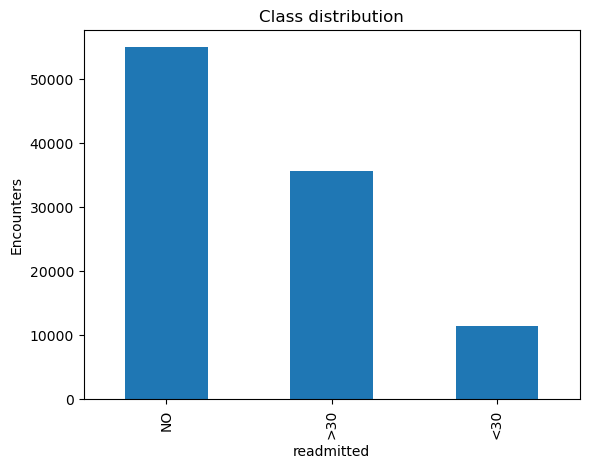

In [5]:
df['readmitted'].value_counts().plot(kind='bar')
plt.title('Class distribution')
plt.ylabel('Encounters')
plt.show()

In [6]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [7]:
# Categorical columns
df.describe(include='object').T
df['age'].value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [ ]:
df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

#  Missingness per column ('?' placeholder; 'None' for the two lab tests)
miss = pd.DataFrame({
    'missing': (df == '?').sum(),
    '%': ((df == '?').mean() * 100).round(2)
})
miss = miss[miss['missing'] > 0].sort_values('%', ascending=False)
miss.loc['A1Cresult (None)']      = [(df['A1Cresult'] == 'None').sum(),
                                     round((df['A1Cresult'] == 'None').mean() * 100, 2)]
miss.loc['max_glu_serum (None)']  = [(df['max_glu_serum'] == 'None').sum(),
                                     round((df['max_glu_serum'] == 'None').mean() * 100, 2)]
miss

,missing,%
weight,98569.0,96.86
medical_specialty,49949.0,49.08
payer_code,40256.0,39.56
race,2273.0,2.23
diag_3,1423.0,1.40
diag_2,358.0,0.35
diag_1,21.0,0.02
A1Cresult (None),0.0,0.00
max_glu_serum (None),0.0,0.00


In [9]:
# Rows with at least one '?'
(df[['weight','payer_code','medical_specialty','race','diag_1','diag_2','diag_3']] == '?').any(axis=1).mean() * 100


98.97509973861605

In [ ]:
#  Is missingness informative? <30 rate when missing vs present + chi-square test
for c in ['weight','payer_code','medical_specialty','race','diag_1','diag_2','diag_3']:
    m = df[c] == '?'
    p = chi2_contingency(pd.crosstab(m, df['readmit_30']))[1]
    print(f"{c:18s} missing: {df.loc[m,'readmit_30'].mean()*100:5.2f}%  "
          f"present: {df.loc[~m,'readmit_30'].mean()*100:5.2f}%  p={p:.2g}")

for c in ['A1Cresult','max_glu_serum']:
    m = df[c] == 'None'
    p = chi2_contingency(pd.crosstab(m, df['readmit_30']))[1]
    print(f"{c:18s} not done: {df.loc[m,'readmit_30'].mean()*100:5.2f}%  "
          f"done: {df.loc[~m,'readmit_30'].mean()*100:5.2f}%  p={p:.2g}")


weight             missing: 11.16%  present: 11.17%  p=1
payer_code         missing: 11.49%  present: 10.94%  p=0.0064
medical_specialty  missing: 11.57%  present: 10.76%  p=4e-05
race               missing:  8.27%  present: 11.23%  p=1.1e-05
diag_1             missing: 23.81%  present: 11.16%  p=0.14
diag_2             missing:  8.10%  present: 11.17%  p=0.079
diag_3             missing:  6.39%  present: 11.23%  p=1.2e-08
A1Cresult          not done:   nan%  done: 11.16%  p=1
max_glu_serum      not done:   nan%  done: 11.16%  p=1


In [ ]:

#  Apply the decisions
df = df.drop(columns=['weight'])
for c in ['payer_code','medical_specialty','race','diag_1','diag_2','diag_3']:
    df[c] = df[c].replace('?', 'Unknown')
df['A1Cresult'] = df['A1Cresult'].replace('None', 'Not tested')
df['max_glu_serum'] = df['max_glu_serum'].replace('None', 'Not tested')

df.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmit_30
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


In [ ]:
df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

# Issue 1: invalid gender
print(df['gender'].value_counts())

# Issue 2: expired / hospice discharges (cannot be readmitted)
EXPIRED, HOSPICE = [11, 19, 20, 21], [13, 14]
dead = df['discharge_disposition_id'].isin(EXPIRED + HOSPICE)
print(df['discharge_disposition_id'].isin(EXPIRED).sum(), df['discharge_disposition_id'].isin(HOSPICE).sum(), dead.sum())
print(df.loc[dead, 'readmitted'].value_counts())

# Issue 3: several encounters per patient
vc = df['patient_nbr'].value_counts()
print((vc > 1).sum(), vc[vc > 1].sum(), vc.max())

# Issue 4: constant columns
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print(const_cols)

# Issue 5: unmapped / "not available" ID codes (see IDs_mapping.csv)
unmapped = {'admission_type_id': [5, 6, 8],
            'discharge_disposition_id': [18, 25, 26],
            'admission_source_id': [9, 15, 17, 20, 21]}
for col, ids in unmapped.items():
    print(col, df[col].isin(ids).sum(), round(df[col].isin(ids).mean() * 100, 2))

# Issue 6: same patient with different gender / race across encounters
multi = df[df['patient_nbr'].isin(vc[vc > 1].index)]
for col, bad in [('gender', 'Unknown/Invalid'), ('race', '?')]:
    k = multi[multi[col] != bad].groupby('patient_nbr')[col].nunique()
    print(col, (k > 1).sum())

#  Apply the correction for (B2 + B3) 
df = pd.read_csv("/Users/iyassaad/Documents/465_Health_informatics/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv")

df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

df = df[(df['gender'] != 'Unknown/Invalid') & ~dead].copy()
df = df.drop(columns=['weight'] + const_cols)
for col, ids in unmapped.items():
    df[col] = df[col].where(~df[col].isin(ids), -1)          # -1 = unknown / not mapped
for c in ['payer_code', 'medical_specialty', 'race', 'diag_1', 'diag_2', 'diag_3']:
    df[c] = df[c].replace('?', 'Unknown')
for c in ['A1Cresult', 'max_glu_serum']:
    df[c] = df[c].replace('None', 'Not tested')
print(df.shape, round(df['readmit_30'].mean() * 100, 2))

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
1652 771 2423
readmitted
NO     2337
<30      43
>30      43
Name: count, dtype: int64
16773 47021 40
['examide', 'citoglipton']
admission_type_id 10396 10.22
discharge_disposition_id 4680 4.6
admission_source_id 7067 6.94
gender 3
race 249
(99340, 48) 11.39


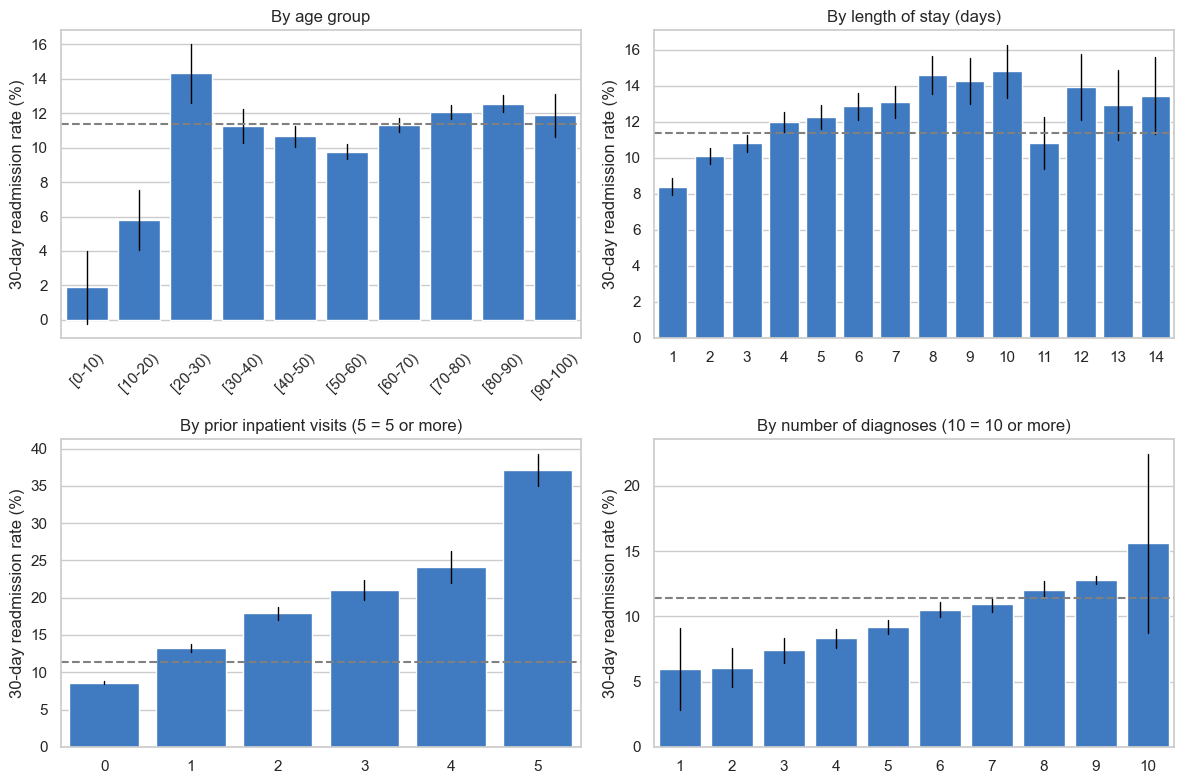

           mean  count
age                   
[0-10)     1.88    160
[10-20)    5.80    690
[20-30)   14.31   1649
[30-40)   11.26   3764
[40-50)   10.66   9607
[50-60)    9.77  17060
[60-70)   11.30  22058
[70-80)   12.06  25329
[80-90)   12.57  16434
[90-100)  11.90   2589 

                   mean  count
time_in_hospital              
1                  8.39  13822
2                 10.09  16891
3                 10.80  17432
4                 11.99  13684
5                 12.27   9749
6                 12.86   7355
7                 13.11   5696
8                 14.59   4270
9                 14.28   2879
10                14.81   2262
11                10.85   1770
12                13.96   1383
13                12.93   1152
14                13.47    995 

                  mean  count
prior_inpatient              
0                 8.59  66242
1                13.25  18984
2                17.93   7300
3                21.03   3271
4                24.14   1574
5             

In [ ]:

sns.set_theme(style='whitegrid')
BLUE = '#2a78d6'

df['readmit_pct'] = df['readmit_30'] * 100          # readmission rate in %
overall = df['readmit_pct'].mean()

# One helper for every "rate by group" bar chart (bars = mean rate, black line = 95% CI)
def rate_plot(x, title, order=None, rotate=0, ax=None):
    ax = sns.barplot(data=df, x=x, y='readmit_pct', order=order, color=BLUE,
                     errorbar=('se', 1.96), err_kws={'color': 'black', 'linewidth': 1}, ax=ax)
    ax.axhline(overall, color='gray', linestyle='--')           # dashed line = overall rate
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('30-day readmission rate (%)')
    ax.tick_params(axis='x', rotation=rotate)

#   age, length of stay, prior inpatient visits, number of diagnoses 
df['prior_inpatient'] = df['number_inpatient'].clip(upper=5)     # 5 = "5 or more"
df['n_diagnoses'] = df['number_diagnoses'].clip(upper=10)        # 10 = "10 or more"

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
rate_plot('age', 'By age group', order=sorted(df['age'].unique()), rotate=45, ax=axes[0, 0])
rate_plot('time_in_hospital', 'By length of stay (days)', ax=axes[0, 1])
rate_plot('prior_inpatient', 'By prior inpatient visits (5 = 5 or more)', ax=axes[1, 0])
rate_plot('n_diagnoses', 'By number of diagnoses (10 = 10 or more)', ax=axes[1, 1])
plt.tight_layout(); plt.show()

for col in ['age', 'time_in_hospital', 'prior_inpatient', 'n_diagnoses']:
    print(df.groupby(col)['readmit_pct'].agg(['mean', 'count']).round(2), '\n')


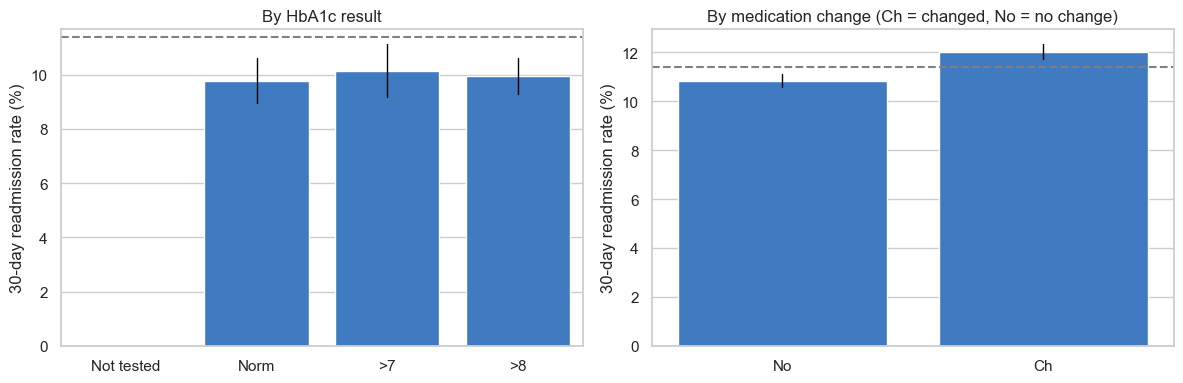

            mean  count
A1Cresult              
>7         10.15   3775
>8          9.94   8137
Norm        9.77   4922
         mean  count
change              
Ch      12.02  46120
No      10.84  53220
                    mean  count
A1C_tested change              
tested     Ch      12.02  46120
           No      10.84  53220


In [ ]:

#  HbA1c testing and medication change 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_plot('A1Cresult', 'By HbA1c result', order=['Not tested', 'Norm', '>7', '>8'], ax=axes[0])
rate_plot('change', 'By medication change (Ch = changed, No = no change)', ax=axes[1])
plt.tight_layout(); plt.show()

print(df.groupby('A1Cresult')['readmit_pct'].agg(['mean', 'count']).round(2))
print(df.groupby('change')['readmit_pct'].agg(['mean', 'count']).round(2))
df['A1C_tested'] = (df['A1Cresult'] != 'Not tested').map({True: 'tested', False: 'not tested'})
print(df.groupby(['A1C_tested', 'change'])['readmit_pct'].agg(['mean', 'count']).round(2))


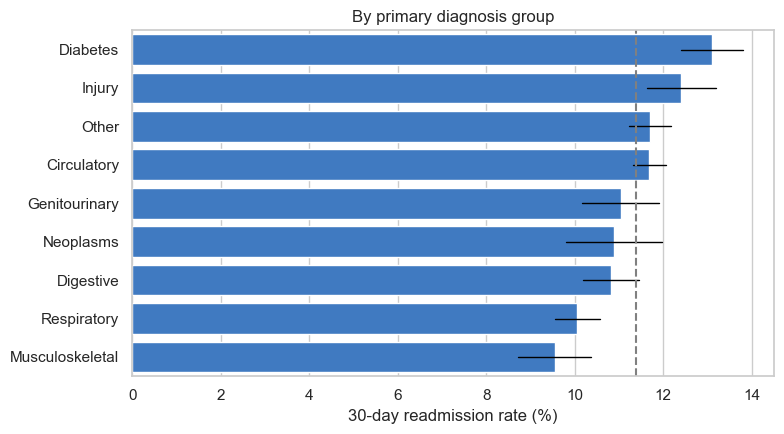

                  mean  count
diag_1_group                 
Diabetes         13.10   8661
Injury           12.41   6851
Other            11.70  17813
Circulatory      11.69  29680
Genitourinary    11.04   5002
Neoplasms        10.89   3131
Digestive        10.82   9333
Respiratory      10.06  13934
Musculoskeletal   9.54   4935


In [ ]:

#  diagnosis categories (ICD-9 codes grouped from diag_1) 
def diag_group(code):
    if code[0] in 'VE': return 'Other'
    try: n = int(float(code))
    except ValueError: return 'Other'     # "Unknown"
    if n == 250: return 'Diabetes'
    if 390 <= n <= 459 or n == 785: return 'Circulatory'
    if 460 <= n <= 519 or n == 786: return 'Respiratory'
    if 520 <= n <= 579 or n == 787: return 'Digestive'
    if 580 <= n <= 629 or n == 788: return 'Genitourinary'
    if 710 <= n <= 739: return 'Musculoskeletal'
    if 800 <= n <= 999: return 'Injury'
    if 140 <= n <= 239: return 'Neoplasms'
    return 'Other'

df['diag_1_group'] = df['diag_1'].apply(diag_group)
order = df.groupby('diag_1_group')['readmit_pct'].mean().sort_values(ascending=False).index

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=df, y='diag_1_group', x='readmit_pct', order=order, color=BLUE, orient='h',
                 errorbar=('se', 1.96), err_kws={'color': 'black', 'linewidth': 1})
ax.axvline(overall, color='gray', linestyle='--')
ax.set_title('By primary diagnosis group'); ax.set_ylabel(''); ax.set_xlabel('30-day readmission rate (%)')
plt.tight_layout(); plt.show()
print(df.groupby('diag_1_group')['readmit_pct'].agg(['mean', 'count']).round(2).sort_values('mean', ascending=False))



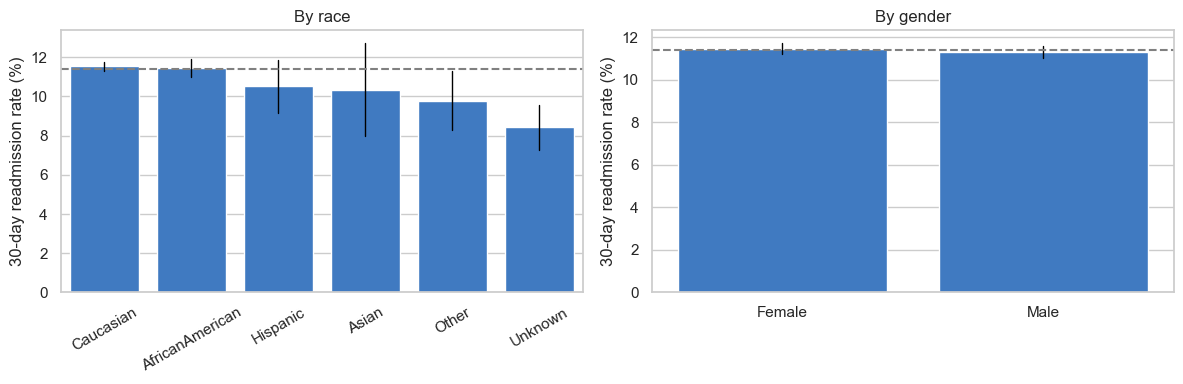

                  mean  count
race                         
Caucasian        11.53  74220
AfricanAmerican  11.45  18772
Hispanic         10.51   2017
Asian            10.35    628
Other             9.79   1471
Unknown           8.42   2232
         mean  count
gender              
Female  11.46  53454
Male    11.30  45886
                 number_inpatient  age_70_plus
race                                          
AfricanAmerican              0.70         0.31
Asian                        0.46         0.44
Caucasian                    0.63         0.49
Hispanic                     0.61         0.26
Other                        0.45         0.33
Unknown                      0.30         0.47


In [ ]:
#   race and gender 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_plot('race', 'By race', order=df.groupby('race')['readmit_pct'].mean().sort_values(ascending=False).index, rotate=30, ax=axes[0])
rate_plot('gender', 'By gender', ax=axes[1])
plt.tight_layout(); plt.show()

print(df.groupby('race')['readmit_pct'].agg(['mean', 'count']).round(2).sort_values('mean', ascending=False))
print(df.groupby('gender')['readmit_pct'].agg(['mean', 'count']).round(2))

# Do the groups differ in need? (prior inpatient visits, share aged 70+)
df['age_70_plus'] = df['age'].isin(['[70-80)', '[80-90)', '[90-100)'])
print(df.groupby('race')[['number_inpatient', 'age_70_plus']].mean().round(2))

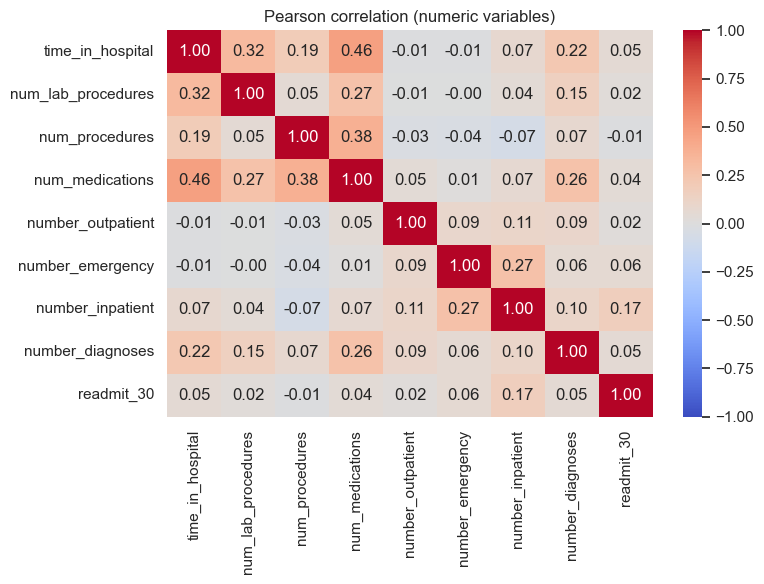

                    pearson  spearman
time_in_hospital      0.047     0.053
num_lab_procedures    0.024     0.024
num_procedures       -0.011    -0.005
num_medications       0.041     0.048
number_outpatient     0.019     0.035
number_emergency      0.061     0.064
number_inpatient      0.168     0.141
number_diagnoses      0.054     0.052
discharge_disposition_id    0.115
medical_specialty           0.061
insulin                     0.045
age                         0.037
payer_code                  0.033
diag_1_group                0.029
metformin                   0.027
diabetesMed                 0.026
admission_source_id         0.024
change                      0.019
admission_type_id           0.017
race                        0.016
A1Cresult                   0.004
gender                      0.003
dtype: float64


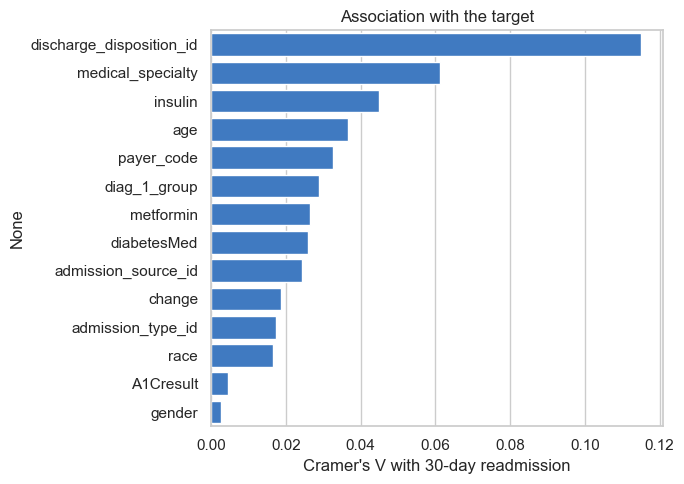

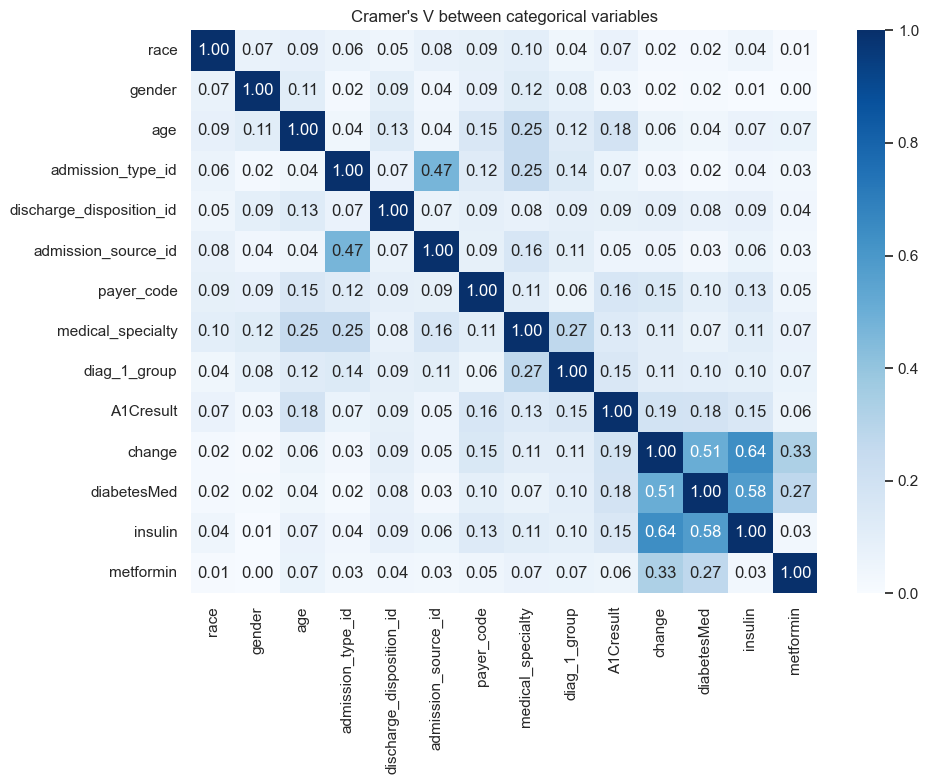

In [ ]:

# Numeric variables: correlation
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

corr = df[num_cols + ['readmit_30']].corr()                      # Pearson
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Pearson correlation (numeric variables)')
plt.tight_layout(); plt.show()

# Correlation with the target (Spearman is added because the visit counts are very skewed)
print(pd.DataFrame({'pearson': df[num_cols].corrwith(df['readmit_30']),
                    'spearman': df[num_cols].corrwith(df['readmit_30'], method='spearman')}).round(3))

# Categorical variables: Cramer's V (0 = no association, 1 = perfect) 
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    n = table.values.sum()
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / n
    chi2 = ((table.values - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

cat_cols = ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id',
            'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1_group',
            'A1Cresult', 'change', 'diabetesMed', 'insulin', 'metformin']

# Each categorical variable vs the target
v_target = pd.Series({c: cramers_v(df[c], df['readmit_30']) for c in cat_cols}).sort_values(ascending=False)
print(v_target.round(3))

plt.figure(figsize=(7, 5))
sns.barplot(x=v_target.values, y=v_target.index, color='#2a78d6')
plt.xlabel("Cramer's V with 30-day readmission"); plt.title('Association with the target')
plt.tight_layout(); plt.show()

# Categorical variables vs each other
V = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cat_cols] for a in cat_cols],
                 index=cat_cols, columns=cat_cols)
plt.figure(figsize=(10, 8))
sns.heatmap(V, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title("Cramer's V between categorical variables")
plt.tight_layout(); plt.show()

In [ ]:
#   Encoding the high-cardinality categorical variables 
cols = ['diag_1', 'diag_2', 'diag_3', 'medical_specialty', 'payer_code',
        'admission_type_id', 'discharge_disposition_id', 'admission_source_id']
before = df[cols].nunique()

# 1) Diagnosis codes -> clinical categories (uses diag_group() from B4)
def diag_category(code):
    return 'Unknown' if code == 'Unknown' else diag_group(code)

for c in ['diag_1', 'diag_2', 'diag_3']:
    df[c + '_cat'] = df[c].apply(diag_category)

# 2) Specialty, payer and ID codes -> keep levels with at least 1% of the rows, merge the rest into "Other"
def group_rare(series, min_share=0.01):
    s = series.astype(str)
    share = s.value_counts(normalize=True)
    return s.where(s.isin(share[share >= min_share].index), 'Other')

for c in ['medical_specialty', 'payer_code', 'admission_type_id',
          'discharge_disposition_id', 'admission_source_id']:
    df[c + '_cat'] = group_rare(df[c])

# 3) Check: number of levels before / after
after = df[[c + '_cat' for c in cols]].nunique()
after.index = cols
print(pd.DataFrame({'before': before, 'after': after}))

# 4) Check: the new levels still separate readmission risk
for c in ['diag_2_cat', 'medical_specialty_cat', 'payer_code_cat']:
    print(df.groupby(c)['readmit_pct'].agg(['mean', 'count']).round(2).sort_values('count', ascending=False), '\n')

                          before  after
diag_1                       716     10
diag_2                       748     10
diag_3                       787     10
medical_specialty             73     11
payer_code                    18     11
admission_type_id              6      5
discharge_disposition_id      20      8
admission_source_id           15      7
                  mean  count
diag_2_cat                   
Circulatory      11.31  31157
Other            11.46  26027
Diabetes         10.64  12705
Respiratory      10.97  10390
Genitourinary    12.00   8147
Digestive        11.64   4088
Injury           11.67   2383
Neoplasms        16.21   2326
Musculoskeletal  10.05   1761
Unknown           8.15    356 

                             mean  count
medical_specialty_cat                   
Unknown                     11.83  48614
InternalMedicine            11.53  14237
Other                       10.20   8199
Emergency/Trauma            11.39   7419
Family/GeneralPractice      12.1

In [ ]:
#  Total prior visits in the previous year
df['total_prior_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']

#  Number of drugs with a dose change (only the drug columns contain "Up" / "Down")
df['n_med_changes'] = df.isin(['Up', 'Down']).sum(axis=1)

#  Comorbidity count: number of different body systems among the 3 diagnoses (from C1)
df['comorbidity_count'] = df[['diag_1_cat', 'diag_2_cat', 'diag_3_cat']].replace('Unknown', np.nan).nunique(axis=1)

#  Discharge group (codes from IDs_mapping.csv)
groups = {1: 'Home', 6: 'Home + health services', 8: 'Home + health services',
          3: 'Nursing facility', 4: 'Nursing facility', 24: 'Nursing facility',
          5: 'Rehab / inpatient care', 22: 'Rehab / inpatient care', 23: 'Rehab / inpatient care',
          2: 'Hospital transfer', 28: 'Hospital transfer', 7: 'Left AMA'}
df['discharge_group'] = df['discharge_disposition_id'].map(groups).fillna('Other / unknown')

# Check: readmission rate (%) for each new feature
print(df.groupby(df['total_prior_visits'].clip(upper=8))['readmit_pct'].mean().round(2), '\n')   # 8 = "8 or more"
print(df.groupby(df['n_med_changes'].clip(upper=3))['readmit_pct'].mean().round(2), '\n')        # 3 = "3 or more"
print(df.groupby('comorbidity_count')['readmit_pct'].mean().round(2), '\n')
print(df.groupby('discharge_group')['readmit_pct'].mean().round(2).sort_values())

total_prior_visits
0     8.32
1    11.82
2    14.98
3    15.74
4    17.64
5    18.68
6    23.84
7    23.09
8    28.45
Name: readmit_pct, dtype: float64 

n_med_changes
0    10.65
1    13.41
2    12.24
3    14.29
Name: readmit_pct, dtype: float64 

comorbidity_count
1    10.11
2    11.57
3    11.51
Name: readmit_pct, dtype: float64 

discharge_group
Home                       9.30
Other / unknown           12.28
Home + health services    12.71
Left AMA                  14.45
Nursing facility          14.56
Hospital transfer         17.34
Rehab / inpatient care    23.10
Name: readmit_pct, dtype: float64


####  Implement Logistic regression, Random forest, SVM and KKN

In [20]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier



In [21]:
SEED = 42

#  Features and target 
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses',
            'total_prior_visits', 'n_med_changes', 'comorbidity_count']
med_cols = [c for c in df.columns if set(df[c].unique()) <= {'No', 'Steady', 'Up', 'Down'}]   # the drug columns
cat_cols = ['race', 'gender', 'age', 'admission_type_id_cat', 'admission_source_id_cat', 'payer_code_cat',
            'medical_specialty_cat', 'diag_1_cat', 'diag_2_cat', 'diag_3_cat', 'discharge_group',
            'A1Cresult', 'max_glu_serum', 'change', 'diabetesMed'] + med_cols


In [22]:
X = df[num_cols + cat_cols]
y = df ['readmit_30']
groups = df['patient_nbr']

#### Train / Test split By Patient the same patiebt never appear in both

In [23]:
#  Train / test split BY PATIENT (the same patient never appears in both) 
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X , y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Positive rate: train {y_train.mean()*100:.2f}% | test {y_test.mean()*100:.2f}%")
print("Patients in both sets:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))


Train: 79,567 rows | Test: 19,773 rows
Positive rate: train 11.40% | test 11.35%
Patients in both sets: 0


In [24]:
#  Preprocessing: scale numeric columns, one-hot encode categorical columns 
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])


In [25]:
#  Four model families and their hyperparameter grids 
models = {
    'Logistic Regression': (LogisticRegression(class_weight='balanced', max_iter=1000),
                            {'model__C': [0.001, 0.01, 0.1, 1]}),
    'Random Forest': (RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=SEED),
                      {'model__max_depth': [8, 12, 16, 20], 'model__min_samples_leaf': [10, 30]}),
    'SVM (linear)': (LinearSVC(class_weight='balanced', dual=False),
                     {'model__C': [0.0001, 0.001, 0.01, 0.1]}),
    'KNN': (KNeighborsClassifier(),
            {'model__n_neighbors': [100, 200, 400, 800, 1600]}),
}

In [26]:
#  Hyperparameter search: grid search with patient-level 3-fold cross-validation 
cv = GroupKFold(n_splits=3)
best_models, summary = {}, []


In [27]:

for name, (model, grid) in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring=['roc_auc', 'average_precision'],
                          refit='roc_auc', n_jobs=-1)
    search.fit(X_train, y_train, groups=groups_train)

    best_models[name] = search.best_estimator_          # refitted on the whole training set (used in D2)
    i = search.best_index_
    summary.append({'model': name, 'best params': search.best_params_,
                    'CV ROC-AUC': round(search.cv_results_['mean_test_roc_auc'][i], 3),
                    '+/- std': round(search.cv_results_['std_test_roc_auc'][i], 3),
                    'CV PR-AUC': round(search.cv_results_['mean_test_average_precision'][i], 3)})

    print(f"\n{name}: every combination tried")                     # documented search
    print(pd.DataFrame(search.cv_results_)[['params', 'mean_test_roc_auc', 'mean_test_average_precision']].round(3).to_string(index=False))

print('\n', pd.DataFrame(summary).to_string(index=False))


Logistic Regression: every combination tried
             params  mean_test_roc_auc  mean_test_average_precision
{'model__C': 0.001}              0.660                        0.206
 {'model__C': 0.01}              0.660                        0.208
  {'model__C': 0.1}              0.658                        0.207
    {'model__C': 1}              0.658                        0.207

Random Forest: every combination tried
                                                 params  mean_test_roc_auc  mean_test_average_precision
 {'model__max_depth': 8, 'model__min_samples_leaf': 10}              0.663                        0.207
 {'model__max_depth': 8, 'model__min_samples_leaf': 30}              0.663                        0.207
{'model__max_depth': 12, 'model__min_samples_leaf': 10}              0.667                        0.211
{'model__max_depth': 12, 'model__min_samples_leaf': 30}              0.667                        0.211
{'model__max_depth': 16, 'model__min_samples_leaf': 10

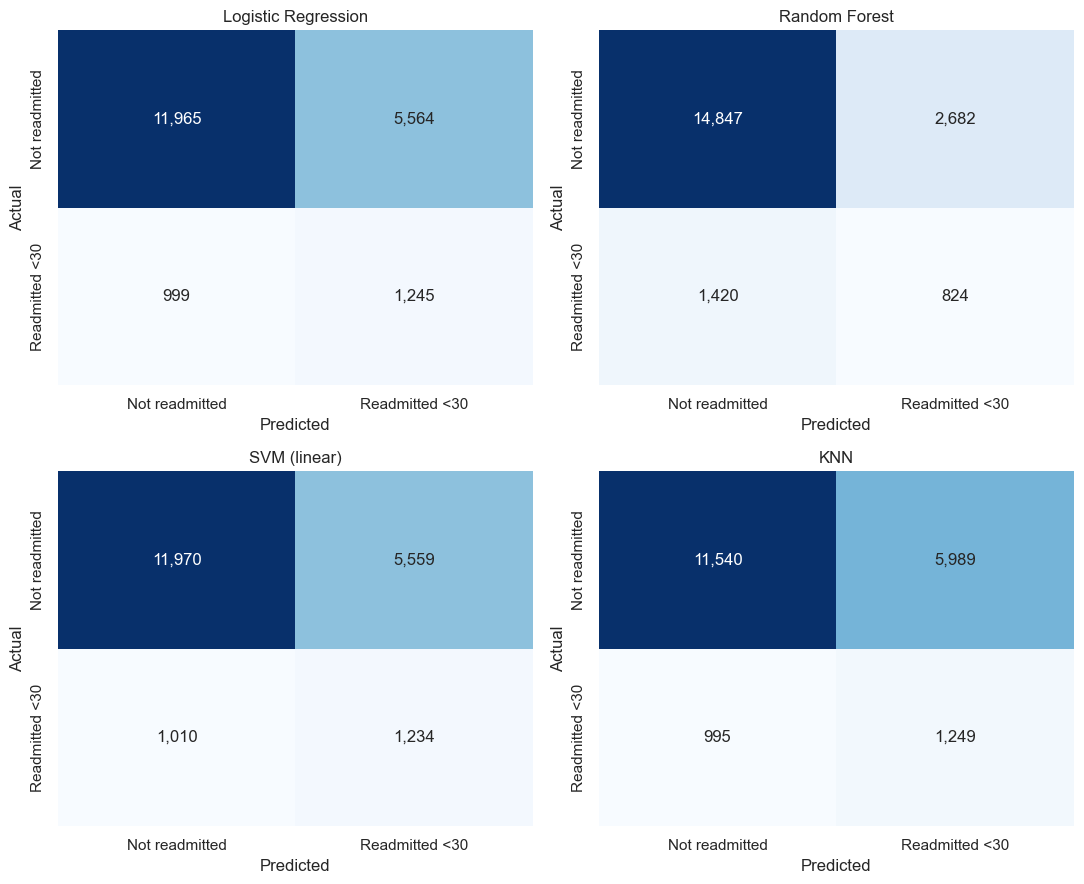

                     accuracy  precision  recall     f1  roc_auc
model                                                           
Logistic Regression     0.668      0.183   0.555  0.275    0.668
Random Forest           0.793      0.235   0.367  0.287    0.680
SVM (linear)            0.668      0.182   0.550  0.273    0.667
KNN                     0.647      0.173   0.557  0.263    0.654


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

rows, preds = [], {}
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, model) in zip(axes.ravel(), best_models.items()):
    # Score used for ROC-AUC (the SVM has no probabilities, so we use its decision function)
    if hasattr(model, 'predict_proba'):
        score = model.predict_proba(X_test)[:, 1]
    else:
        score = model.decision_function(X_test)

    # Class labels: default threshold, except KNN (it has no class weights, so its probabilities
    # rarely reach 0.5): for KNN the threshold is the readmission rate in the training set
    if name == 'KNN':
        pred = (score >= y_train.mean()).astype(int)
    else:
        pred = model.predict(X_test)
    preds[name] = pred

    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred),
                 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred),
                 'roc_auc': roc_auc_score(y_test, score)})

    cm = confusion_matrix(y_test, pred)                # rows = actual, columns = predicted
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Not readmitted', 'Readmitted <30'],
                yticklabels=['Not readmitted', 'Readmitted <30'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.tight_layout(); plt.show()

results = pd.DataFrame(rows).set_index('model').round(3)
print(results)


In [ ]:
# A model that predicts not readmitted for every patient
baseline = np.zeros(len(y_test), dtype=int)
results.loc['Predict nobody'] = [accuracy_score(y_test, baseline),
                                 precision_score(y_test, baseline, zero_division=0),
                                 recall_score(y_test, baseline),
                                 f1_score(y_test, baseline),
                                 roc_auc_score(y_test, baseline)]

# How many of the real readmissions does each one catch?
caught = {name: int(((p == 1) & (y_test == 1)).sum()) for name, p in preds.items()}
caught['Predict nobody'] = 0
results['readmissions caught'] = pd.Series(caught)

print(f"Readmissions in the test set: {y_test.sum():,} of {len(y_test):,} ({y_test.mean()*100:.2f}%)")
results.round(3)


Readmissions in the test set: 2,244 of 19,773 (11.35%)


,accuracy,precision,recall,f1,roc_auc,readmissions caught
model,,,,,,
Logistic Regression,0.668,0.183,0.555,0.275,0.668,1245
Random Forest,0.793,0.235,0.367,0.287,0.680,824
SVM (linear),0.668,0.182,0.550,0.273,0.667,1234
KNN,0.647,0.173,0.557,0.263,0.654,1249
Predict nobody,0.887,0.000,0.000,0.000,0.500,0


discharge_group            0.0440
number_inpatient           0.0261
total_prior_visits         0.0156
diag_1_cat                 0.0053
age                        0.0042
payer_code_cat             0.0036
diabetesMed                0.0032
medical_specialty_cat      0.0027
admission_source_id_cat    0.0026
metformin                  0.0025
dtype: float64


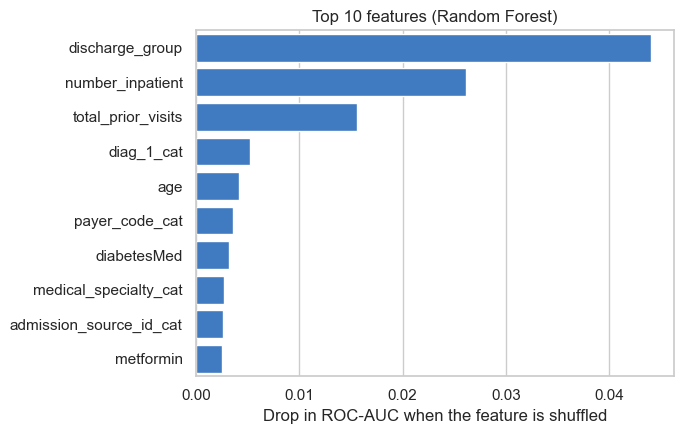

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import recall_score, precision_score

rf = best_models['Random Forest']
pred = preds['Random Forest']

#   Feature importance (drop in ROC-AUC when a feature is shuffled) 
imp = permutation_importance(rf, X_test, y_test, scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(importance.head(10).round(4))

plt.figure(figsize=(7, 4.5))
sns.barplot(x=importance.head(10).values, y=importance.head(10).index, color='#2a78d6')
plt.xlabel('Drop in ROC-AUC when the feature is shuffled'); plt.ylabel(''); plt.title('Top 10 features (Random Forest)')
plt.tight_layout(); plt.show()

In [ ]:


#   Error analysis: missed readmissions (false negatives) 
fn = (pred == 0) & (y_test == 1)
tp = (pred == 1) & (y_test == 1)
print(f"Missed: {fn.sum():,} of {y_test.sum():,} readmissions ({fn.sum() / y_test.sum() * 100:.0f}%)")

cols = ['total_prior_visits', 'time_in_hospital', 'num_medications', 'number_diagnoses', 'n_med_changes']
print(pd.DataFrame({'missed (FN)': X_test[fn][cols].mean(), 'caught (TP)': X_test[tp][cols].mean(),
                    'all patients': X_test[cols].mean()}).round(2))
print(pd.DataFrame({'missed (FN)': X_test[fn]['discharge_group'].value_counts(normalize=True),
                    'caught (TP)': X_test[tp]['discharge_group'].value_counts(normalize=True)}).round(2))
print(X_test[fn][cols + ['discharge_group', 'age']].sample(5, random_state=SEED))     # a sample of missed patients


Missed: 1,420 of 2,244 readmissions (63%)
                    missed (FN)  caught (TP)  all patients
total_prior_visits         0.91         4.12          1.19
time_in_hospital           4.49         5.03          4.36
num_medications           16.47        17.59         15.90
number_diagnoses           7.53         7.83          7.40
n_med_changes              0.31         0.42          0.29
                        missed (FN)  caught (TP)
discharge_group                                 
Home                           0.57         0.36
Home + health services         0.15         0.16
Hospital transfer              0.03         0.05
Left AMA                       0.01         0.01
Nursing facility               0.17         0.21
Other / unknown                0.06         0.05
Rehab / inpatient care         0.02         0.17
       total_prior_visits  time_in_hospital  num_medications  \
3049                    2                 2                8   
19571                   1          

In [ ]:

#   Recall and precision by subgroup 
test = X_test[['gender', 'race', 'age']].copy()
test['age_group'] = test['age'].map({'[0-10)': '<30', '[10-20)': '<30', '[20-30)': '<30',
                                     '[30-40)': '30-49', '[40-50)': '30-49', '[50-60)': '50-69',
                                     '[60-70)': '50-69', '[70-80)': '70+', '[80-90)': '70+', '[90-100)': '70+'})
test['y'], test['pred'] = y_test, pred

def by_group(col):
    rows = []
    for name, g in test.groupby(col):
        rows.append({col: name, 'n': len(g), 'readmitted': g['y'].sum(),
                     'recall': recall_score(g['y'], g['pred']),
                     'precision': precision_score(g['y'], g['pred'], zero_division=0),
                     'flagged %': g['pred'].mean() * 100})
    return pd.DataFrame(rows).set_index(col).round(2)

for col in ['age_group', 'gender', 'race']:
    print(by_group(col), '\n')


              n  readmitted  recall  precision  flagged %
age_group                                                
30-49      2666         270    0.34       0.23      14.89
50-69      7823         881    0.35       0.27      14.82
70+        8752        1023    0.36       0.20      20.89
<30         532          70    0.74       0.43      22.93 

            n  readmitted  recall  precision  flagged %
gender                                                 
Female  10726        1228    0.39       0.24      18.49
Male     9047        1016    0.34       0.22      16.83 

                     n  readmitted  recall  precision  flagged %
race                                                            
AfricanAmerican   3697         399    0.34       0.20      17.91
Asian              116          10    0.40       0.22      15.52
Caucasian        14813        1736    0.38       0.24      18.11
Hispanic           398          36    0.39       0.23      15.33
Other              302          31

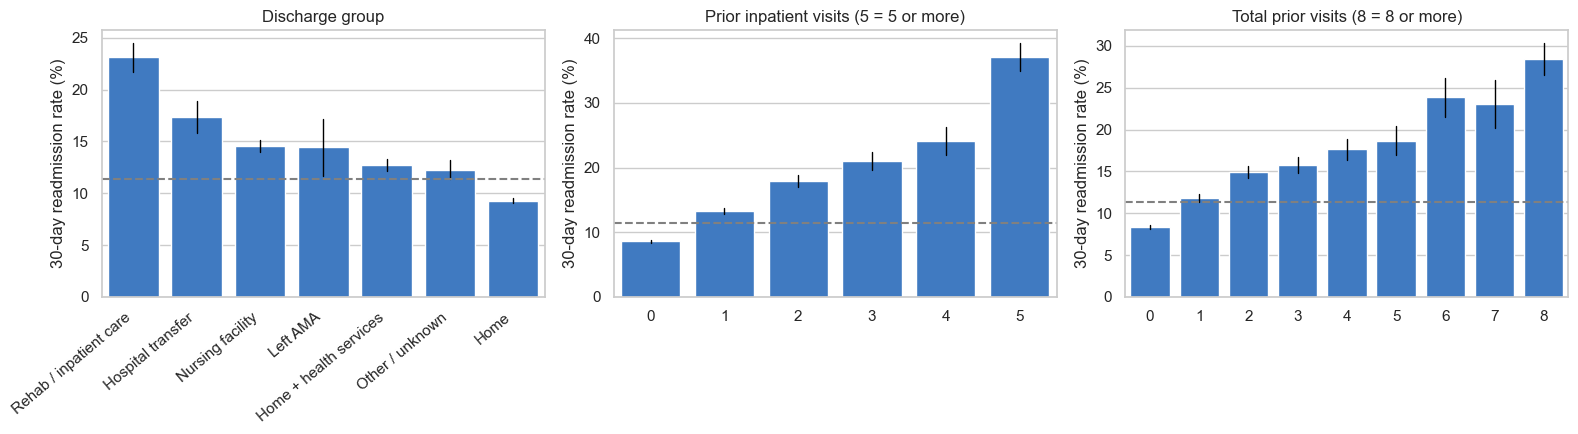

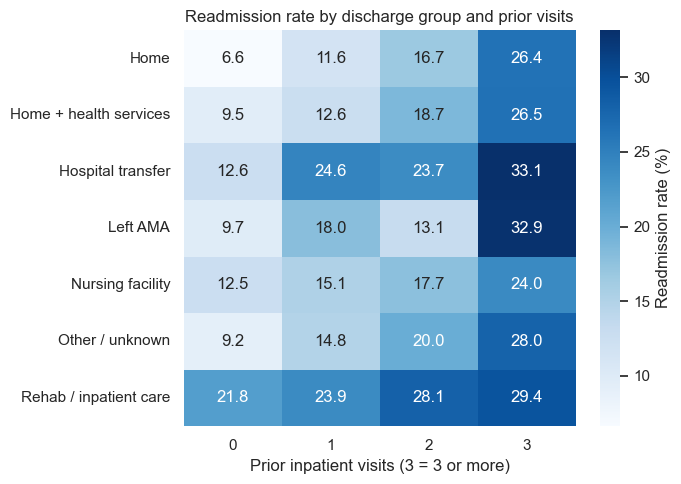

Logistic Regression: following up the top 20% of patients reaches 38.4% of readmissions
Random Forest: following up the top 20% of patients reaches 40.2% of readmissions
SVM (linear): following up the top 20% of patients reaches 38.0% of readmissions
KNN: following up the top 20% of patients reaches 36.9% of readmissions


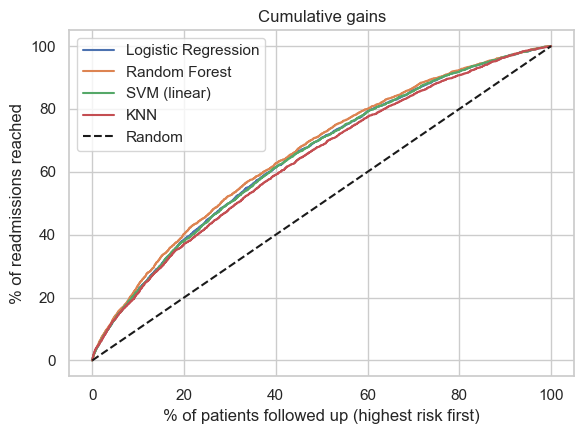

In [33]:
#  Readmission rate by the three most important features 
df['prior_visits_cap'] = df['total_prior_visits'].clip(upper=8)
order = df.groupby('discharge_group')['readmit_pct'].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
rate_plot('discharge_group', 'Discharge group', order=order, ax=axes[0])
plt.setp(axes[0].get_xticklabels(), rotation=40, ha='right')
rate_plot('prior_inpatient', 'Prior inpatient visits (5 = 5 or more)', ax=axes[1])
rate_plot('prior_visits_cap', 'Total prior visits (8 = 8 or more)', ax=axes[2])
plt.tight_layout(); plt.show()

#  The two strongest features together 
rate = df.pivot_table(index='discharge_group', columns=df['number_inpatient'].clip(upper=3), values='readmit_pct')
plt.figure(figsize=(7, 5))
sns.heatmap(rate, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Readmission rate (%)'})
plt.xlabel('Prior inpatient visits (3 = 3 or more)'); plt.ylabel('')
plt.title('Readmission rate by discharge group and prior visits')
plt.tight_layout(); plt.show()

#  How well do the models rank patients? (cumulative gains) 
plt.figure(figsize=(6, 4.5))
for name, model in best_models.items():
    score = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    caught = np.cumsum(y_test.values[np.argsort(-score)]) / y_test.sum() * 100
    plt.plot(np.arange(1, len(score) + 1) / len(score) * 100, caught, label=name)
    print(f"{name}: following up the top 20% of patients reaches {caught[int(len(score) * 0.2) - 1]:.1f}% of readmissions")
plt.plot([0, 100], [0, 100], 'k--', label='Random')
plt.xlabel('% of patients followed up (highest risk first)'); plt.ylabel('% of readmissions reached')
plt.title('Cumulative gains'); plt.legend()
plt.tight_layout(); plt.show()